# Pick a Place: data preparation

This notebook builds the two files the **Pick a Place** explorer (`index.html` in this folder) loads:

| File | What it holds |
|---|---|
| `data/place-warming.json` | For every map square: warming from 2020 to 2100 under SSP1-2.6, SSP2-4.5 and SSP5-8.5, plus the global average |
| `data/countries.geojson` | Country outlines in GeoJSON, so the page only needs D3 (no `topojson-client`) |

**How each place's numbers are made**

1. Load monthly near-surface air temperature for the three scenarios (GISS-E2-1-G, run `r1i1p3f1`, same as Project 3).
2. Average the 12 months of each year.
3. Merge 2×2 model cells into 4° × 5° squares, the same grid as the Project 3 map, so the file stays small.
4. Express temperature as **warming since 2015–2024**. The baseline is the 2015–2024 average of all three scenarios, so every scenario starts from the same point and their differences are kept.
5. Smooth with a **10-year rolling mean** (2015–2019 are included so 2020 gets a full window), then keep 2020–2100.

Run all cells from this folder (`pick-a-place-model/`). Loading the data takes a minute or two.

In [1]:
import os
os.environ["GCSFS_EXPERIMENTAL_ZB_HNS_SUPPORT"] = "false"

import json
import urllib.request
from pathlib import Path

import gcsfs
import numpy as np
import xarray as xr
from matplotlib import pyplot as plt

%matplotlib inline
%config InlineBackend.figure_format = 'retina'

OUT = Path('data')
OUT.mkdir(exist_ok=True)

SCENARIOS = ['ssp126', 'ssp245', 'ssp585']
STORE = "gs://cmip6/CMIP6/ScenarioMIP/NASA-GISS/GISS-E2-1-G/{scenario}/r1i1p3f1/Amon/tas/gn/v20200115/"

BASELINE = slice(2015, 2024)   # "warming since" reference period
SHOW = slice(2020, 2100)       # years shown on the page
LATE = slice(2091, 2100)       # "end of century" used in the readout

## 1. Load the scenarios and average each year

In [2]:
gcs = gcsfs.GCSFileSystem(token='anon')

def annual_celsius(scenario):
    ds = xr.open_zarr(gcs.get_mapper(STORE.format(scenario=scenario)), consolidated=True)
    tas = ds.tas.sel(time=slice('2015', '2100')) - 273.15          # Kelvin -> °C
    return tas.groupby('time.year').mean().drop_vars('height', errors='ignore').load()

annual_full = xr.Dataset({s: annual_celsius(s) for s in SCENARIOS})
annual_full

<xarray.Dataset> Size: 13MB
Dimensions:  (lat: 90, lon: 144, year: 86)
Coordinates:
  * lat      (lat) float64 720B -89.0 -87.0 -85.0 -83.0 ... 83.0 85.0 87.0 89.0
  * lon      (lon) float64 1kB 1.25 3.75 6.25 8.75 ... 351.2 353.8 356.2 358.8
  * year     (year) int64 688B 2015 2016 2017 2018 2019 ... 2097 2098 2099 2100
Data variables:
    ssp126   (year, lat, lon) float32 4MB -49.04 -49.04 -49.04 ... -15.07 -15.07
    ssp245   (year, lat, lon) float32 4MB -46.37 -46.37 -46.37 ... -14.22 -14.22
    ssp585   (year, lat, lon) float32 4MB -46.87 -46.87 -46.87 ... -8.527 -8.527

## 2. Warming since 2015–2024, smoothed

`smooth` is the same 10-year rolling mean used for the Year × Latitude heatmap.

In [3]:
def smooth(x):
    return x.rolling(year=10, center=True, min_periods=5).mean().sel(year=SHOW)

def warming_since_baseline(x):
    baseline = x.sel(year=BASELINE).to_array().mean(['variable', 'year'])   # shared by all three scenarios
    return x - baseline

# Global average (area-weighted, computed on the full-resolution grid)
weights = np.cos(np.deg2rad(annual_full.lat))
global_warming = warming_since_baseline(annual_full.weighted(weights).mean(['lat', 'lon']))
global_10yr = smooth(global_warming)
global_late = global_warming.sel(year=LATE).mean('year')

# Map squares: the model's native grid, 2° lat x 2.5° lon (90 x 144 = 12,960 squares)
annual = annual_full
warming = warming_since_baseline(annual)
warming_10yr = smooth(warming)
late = warming.sel(year=LATE).mean('year')
late_gap = late['ssp585'] - late['ssp126']

print('squares:', warming_10yr.sizes['lat'], 'x', warming_10yr.sizes['lon'], '=',
      warming_10yr.sizes['lat'] * warming_10yr.sizes['lon'])
print('global warming by 2091-2100:', {s: round(float(global_late[s]), 2) for s in SCENARIOS})
print(f"end-of-century gap across squares: {float(late_gap.min()):.1f} to {float(late_gap.max()):.1f} °C "
      f"(global {float(global_late['ssp585'] - global_late['ssp126']):.1f} °C)")

squares: 90 x 144 = 12960
global warming by 2091-2100: {'ssp126': 0.92, 'ssp245': 1.57, 'ssp585': 3.34}
end-of-century gap across squares: -3.2 to 7.0 °C (global 2.4 °C)


## 3. Preview: what one place looks like

This is the chart the explorer draws when a reader picks a place. Change `NAME`, `LAT`, `LON` to try others.

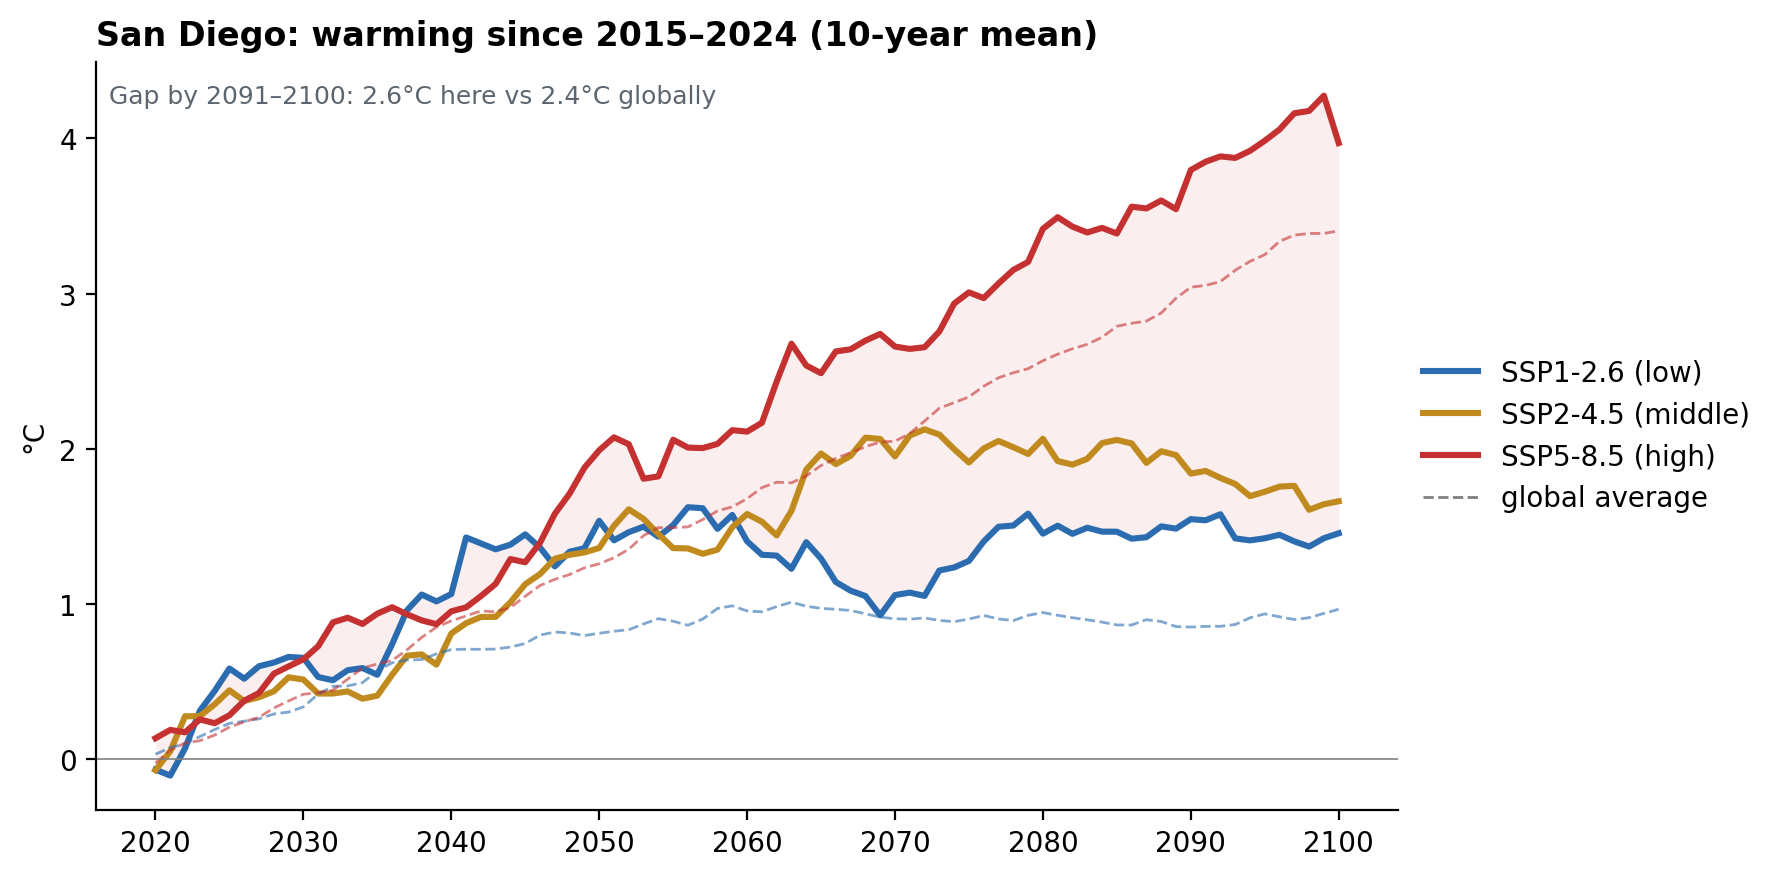

In [4]:
COLORS = {'ssp126': '#2b6cb0', 'ssp245': '#c08a1e', 'ssp585': '#c53030'}
LABELS = {'ssp126': 'SSP1-2.6 (low)', 'ssp245': 'SSP2-4.5 (middle)', 'ssp585': 'SSP5-8.5 (high)'}

def place(lat, lon):
    return warming_10yr.sel(lat=lat, lon=lon % 360, method='nearest')

def plot_place(name, lat, lon):
    p = place(lat, lon)
    gap = float(late_gap.sel(lat=lat, lon=lon % 360, method='nearest'))
    global_gap = float(global_late['ssp585'] - global_late['ssp126'])

    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.fill_between(p.year, p['ssp126'], p['ssp585'], color=COLORS['ssp585'], alpha=0.08, lw=0)
    for s in SCENARIOS:
        ax.plot(p.year, p[s], color=COLORS[s], lw=2.2, label=LABELS[s])
    for s in ['ssp126', 'ssp585']:
        ax.plot(global_10yr.year, global_10yr[s], color=COLORS[s], lw=1, ls='--', alpha=0.6)
    ax.plot([], [], color='grey', lw=1, ls='--', label='global average')
    ax.axhline(0, color='grey', lw=0.6)
    ax.set_title(f'{name}: warming since 2015–2024 (10-year mean)', loc='left', fontweight='bold')
    ax.set_ylabel('°C')
    ax.text(0.01, 0.97, f'Gap by 2091–2100: {gap:.1f}°C here vs {global_gap:.1f}°C globally',
            transform=ax.transAxes, va='top', fontsize=9, color='#5c6670')
    ax.legend(frameon=False, loc='center left', bbox_to_anchor=(1, 0.5))
    ax.spines[['top', 'right']].set_visible(False)
    fig.tight_layout()
    plt.show()

NAME, LAT, LON = 'San Diego', 32.7, -117.2
plot_place(NAME, LAT, LON)

## 4. Export `data/place-warming.json`

One entry per map square. Longitudes are converted from 0–360 to −180–180 for D3's map projection. Values are rounded to 0.01 °C.

In [5]:
years = warming_10yr.year.values.tolist()
# float32 -> float64 before rounding, otherwise 1.23 is written as 1.2300000190734863
# Yearly series are rounded to 0.1 °C (what the page displays) to keep the native-grid file small
values = warming_10yr.to_array().transpose('variable', 'lat', 'lon', 'year').astype('float64').round(1).values   # (scenario, lat, lon, year)
late_values = late.to_array().transpose('variable', 'lat', 'lon').astype('float64').round(2).values

cells = []
for i, lat in enumerate(warming_10yr.lat.values):
    for j, lon in enumerate(warming_10yr.lon.values):
        cell = {'lat': float(lat), 'lon': float((lon + 180) % 360 - 180)}
        for k, s in enumerate(SCENARIOS):
            cell[s] = values[k, i, j].tolist()
        cell['late'] = late_values[:, i, j].tolist()      # 2091–2100 mean, same scenario order
        cells.append(cell)

payload = {
    'model': 'GISS-E2-1-G r1i1p3f1',
    'baseline': '2015–2024',
    'late': '2091–2100',
    'smoothing': '10-year rolling mean',
    'cellSize': [2.5, 2],                                   # [degrees lon, degrees lat]
    'scenarios': SCENARIOS,
    'years': years,
    'global': {
        **{s: global_10yr[s].astype('float64').round(2).values.tolist() for s in SCENARIOS},
        'late': [round(float(global_late[s]), 2) for s in SCENARIOS],
    },
    'cells': cells,
}

target = OUT / 'place-warming.json'
target.write_text(json.dumps(payload, separators=(',', ':')))
print(f'{len(cells)} squares, {target.stat().st_size / 1e6:.1f} MB')

12960 squares, 13.8 MB


## 5. Export `data/countries.geojson`

The world-atlas outlines come as TopoJSON, which normally needs the `topojson-client` library in the browser. To keep the page D3-only, we decode it to GeoJSON here.

In [6]:
# Country outlines are only downloaded if data/countries.geojson is missing.
WORLD_ATLAS = 'https://cdn.jsdelivr.net/npm/world-atlas@2/countries-110m.json'

def topojson_to_geojson(topo, object_name, digits=2):
    (sx, sy), (tx, ty) = topo['transform']['scale'], topo['transform']['translate']

    arcs = []                                  # decode delta-encoded, quantized arcs
    for arc in topo['arcs']:
        x = y = 0
        points = []
        for dx, dy in arc:
            x, y = x + dx, y + dy
            points.append([round(x * sx + tx, digits), round(y * sy + ty, digits)])
        arcs.append(points)

    def ring(indices):                         # negative index = arc reversed (~i)
        points = []
        for i in indices:
            arc = arcs[i] if i >= 0 else arcs[~i][::-1]
            points.extend(arc if not points else arc[1:])
        return points

    features = []
    for g in topo['objects'][object_name]['geometries']:
        if g['type'] == 'Polygon':
            coords = [ring(r) for r in g['arcs']]
        elif g['type'] == 'MultiPolygon':
            coords = [[ring(r) for r in polygon] for polygon in g['arcs']]
        else:
            continue
        features.append({'type': 'Feature', 'id': g.get('id'), 'properties': g.get('properties', {}),
                         'geometry': {'type': g['type'], 'coordinates': coords}})
    return {'type': 'FeatureCollection', 'features': features}

target = OUT / 'countries.geojson'
if target.exists():
    print(f'{target} already exists, skipping download')
else:
    with urllib.request.urlopen(WORLD_ATLAS) as response:
        topo = json.load(response)
    countries = topojson_to_geojson(topo, 'countries')
    target.write_text(json.dumps(countries, separators=(',', ':')))
    print(f"{len(countries['features'])} countries, {target.stat().st_size / 1e3:.0f} KB")

data\countries.geojson already exists, skipping download
